In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
df.shape#Step 1: Check the size of the data #df.shape shows the number of rows and columns in the dataset.

(8807, 12)

In [3]:
pip install notebook pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


#Step 1: Check the size of the data
#`df.shape` shows the number of rows and columns in the dataset.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
df.isnull().sum()


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")

In [8]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), errors="coerce")
df["year_added"] = df["date_added"].dt.year
df[["date_added", "year_added"]].head()

,date_added,year_added
0,2021-09-25,2021.0
1,2021-09-24,2021.0
2,2021-09-24,2021.0
3,2021-09-24,2021.0
4,2021-09-24,2021.0


In [9]:
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
year_added      10
dtype: int64

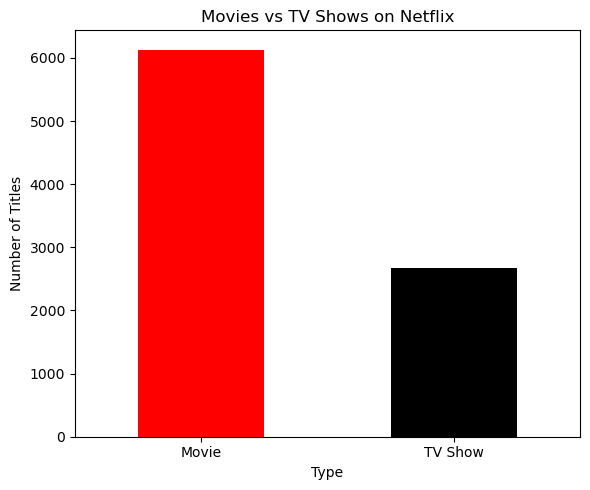

In [10]:
df["type"].value_counts().plot(kind="bar", color=["red", "black"], figsize=(6,5))
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
df["type"].value_counts(normalize=True) * 100

Movie      69.615079
TV Show    30.384921
Name: type, dtype: float64

**Insight:** Movies make up about 70% of Netflix's catalog, 
more than double the number of TV shows. This suggests Netflix's library is built mainly around movies.

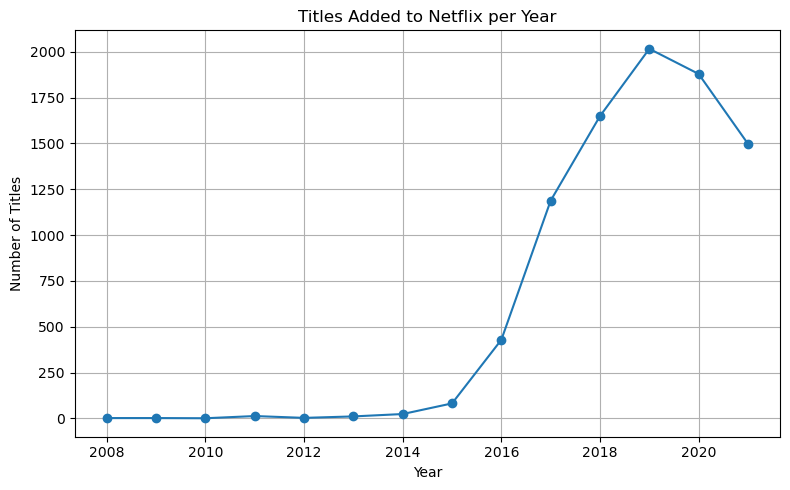

In [12]:
df["year_added"].value_counts().sort_index().plot(kind="line", marker="o", figsize=(8,5))
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

**Insight:** Netflix added very few titles before 2015, then grew its catalog sharply from 2016, peaking at around 2,000 titles in 2019. The drop in 2020 and 2021 may partly be because the data for 2021 is incomplete (it ends in September 2021).

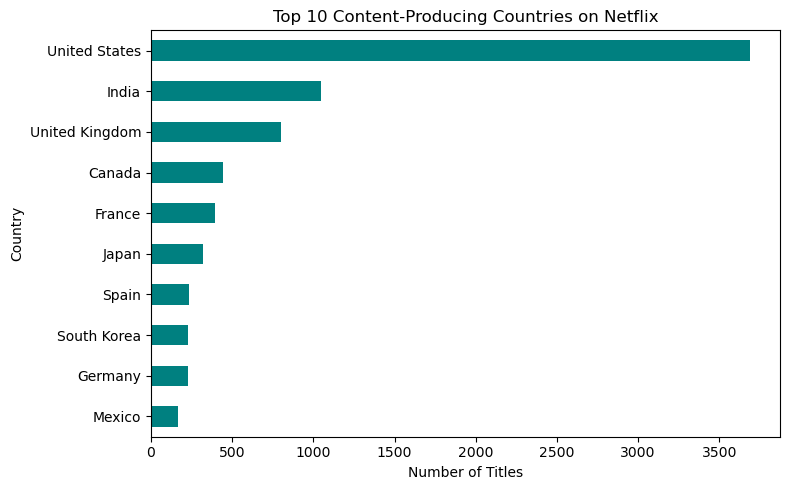

In [13]:
top_countries = (df[df["country"] != "Unknown"]["country"]
                 .str.split(", ").explode().value_counts().head(10))
top_countries.sort_values().plot(kind="barh", figsize=(8,5), color="teal")
plt.title("Top 10 Content-Producing Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

**Insight:** The United States produces by far the most Netflix content, with about 3,700 titles, more than three times the next country. India and the United Kingdom follow, showing that Netflix's catalog is led by US content but has strong international contributions.

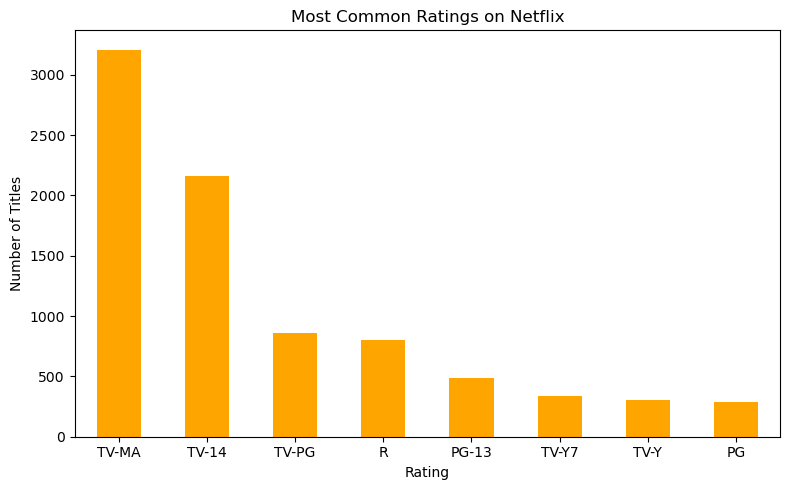

In [14]:
df["rating"].value_counts().head(8).plot(kind="bar", color="orange", figsize=(8,5))
plt.title("Most Common Ratings on Netflix")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** TV-MA (mature audiences) is the most common rating with about 3,200 titles, followed by TV-14 with about 2,150. This shows Netflix's catalog is aimed mainly at adults and teenagers, while content for young children (TV-Y, TV-Y7) makes up a much smaller share.

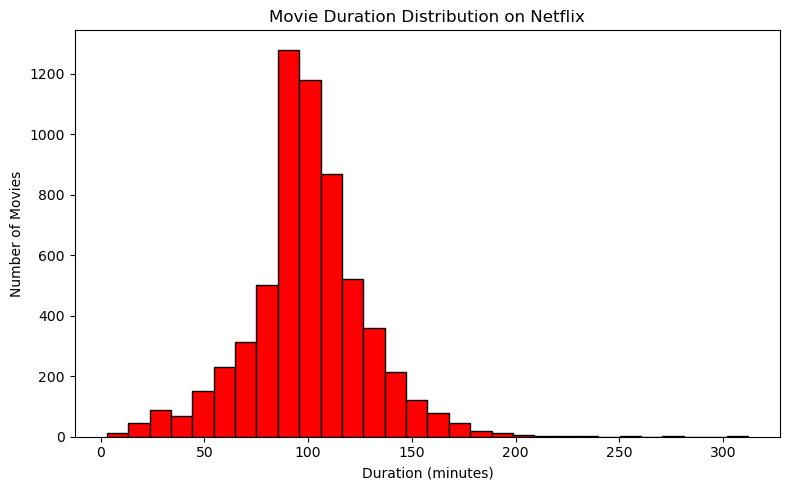

In [15]:
movies = df[df["type"] == "Movie"].copy()
movies["minutes"] = movies["duration"].str.replace(" min", "").astype(float)

plt.figure(figsize=(8,5))
plt.hist(movies["minutes"].dropna(), bins=30, color="red", edgecolor="black")
plt.title("Movie Duration Distribution on Netflix")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

**Insight:** Most Netflix movies run between 80 and 120 minutes, with the peak at around 90 to 100 minutes. Very short and very long movies are rare, and a few outliers run beyond 200 minutes.

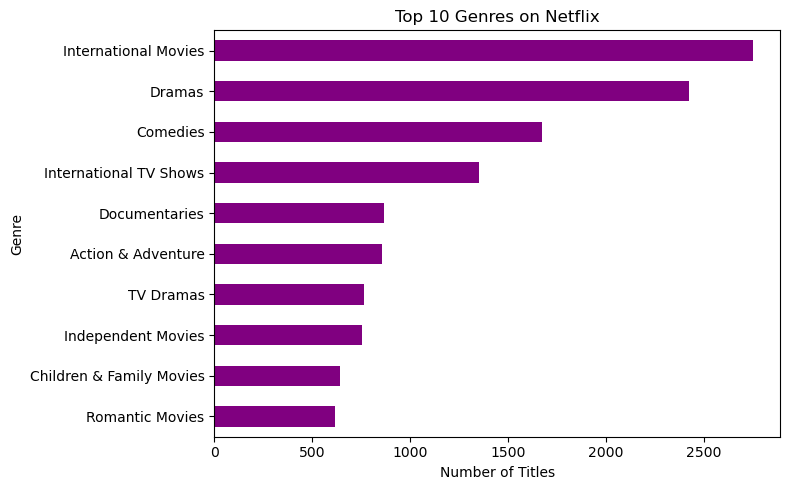

In [16]:
genres = df["listed_in"].str.split(", ").explode().value_counts().head(10)
genres.sort_values().plot(kind="barh", figsize=(8,5), color="purple")
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

**Insight:** International Movies is the largest genre with about 2,750 titles, followed by Dramas and Comedies. International content appears twice in the top 5 (movies and TV shows), showing Netflix's strong focus on global content. Note that a title can belong to more than one genre.

## Conclusion

Key findings from the Netflix titles analysis:

1. **Movies dominate the catalog:** about 70% of titles are movies and 30% are TV shows.
2. **Rapid growth after 2015:** Netflix added far more titles each year from 2016, peaking around 2019.
3. **Global but US-led:** the United States produces the most content, while International Movies is the top genre and India and the UK follow in volume.

Most content is rated for mature audiences (TV-MA) or teens (TV-14), and the typical movie runs about 90 to 100 minutes.